# Analysis of Covid-19 papers

**Master:** Physics of Data \
**Course:** Management and Analysis of Physics Dataset - Module B (MAPD-B) \
**Professor:** Jacopo Pazzini \
**Students:** Polina Gridiaeva, Andres David Rojas Lozano, Elena Niero, Gabriela Landinez Rangel

## Task 1: Word count distributed algorithm

### Spark set up

In [ ]:
# Create a spark session including modules to connect to s3
# Number of cores per executor and number of executors: cores and ex
# These are set for the main word count run

from pyspark.sql import SparkSession
cores = 8
ex = 3
spark = SparkSession.builder \
    .master("spark://master:7077")\
    .appName("polly")\
    .config('spark.jars.packages', 'org.apache.hadoop:hadoop-aws:3.4.1,org.apache.hadoop:hadoop-common:3.4.1')\
    .config("spark.cores.max", cores*ex) \
    .config("spark.executor.cores", cores) \
    .config("spark.executor.instances", ex) \
    .config("spark.executor.memory", "3g") \
    .config("spark.local.dir", "/mnt/vol2/spark-tmp")\
    .config("spark.worker.dir", "/mnt/vol2/spark-tmp") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")\
    .config("spark.sql.execution.arrow.pyspark.fallback.enabled", "false")\
    .config('spark.hadoop.fs.s3a.aws.credentials.provider', 'org.apache.hadoop.fs.s3a.SimpleAWSCredentialsProvider')\
    .config('spark.hadoop.fs.s3a.access.key', 'ACCESS KEY')\
    .config('spark.hadoop.fs.s3a.secret.key', 'SECRET KEY')\
    .config('spark.hadoop.fs.s3a.endpoint', 'https://cloud-areapd.pd.infn.it:5210')\
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .config("spark.hadoop.fs.s3a.metadatastore.impl", "org.apache.hadoop.fs.s3a.s3guard.NullMetadataStore") \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .config("spark.hadoop.fs.s3a.connection.ssl.enabled","false") \
    .config("com.amazonaws.sdk.disableCertChecking","true") \
    .getOrCreate()

:: loading settings :: url = jar:file:/mnt/vol2/env/jup_env/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/ubuntu/.ivy2.5.2/cache
The jars for the packages stored in: /home/ubuntu/.ivy2.5.2/jars
org.apache.hadoop#hadoop-aws added as a dependency
org.apache.hadoop#hadoop-common added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-3f2c4767-bc1c-4f22-8d9f-5cef104389a4;1.0
	confs: [default]
	found org.apache.hadoop#hadoop-aws;3.4.1 in central
	found software.amazon.awssdk#bundle;2.24.6 in central
	found org.wildfly.openssl#wildfly-openssl;1.1.3.Final in central
	found org.apache.hadoop#hadoop-common;3.4.1 in central
	found org.apache.hadoop.thirdparty#hadoop-shaded-protobuf_3_25;1.3.0 in central
	found org.apache.hadoop#hadoop-annotations;3.4.1 in central
	found org.apache.hadoop.thirdparty#hadoop-shaded-guava;1.3.0 in central
	found com.google.guava#guava;27.0-jre in c

In [2]:
sc = spark.sparkContext
sc

<SparkContext master=spark://master:7077 appName=polly>

### Import all the necessary libraries

In [3]:
import matplotlib.pyplot as plt
import json
import sys
import re
import socket
from collections import Counter
import os
import nltk  # Natural Language Toolkit
nltk.download('stopwords')  # download NLTK's English stopword list
from nltk.corpus import stopwords
import time
import pandas as pd
from pathlib import Path
import numpy as np

[nltk_data] Downloading package stopwords to /home/ubuntu/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### Text Extraction and Preprocessing
Before counting words, the raw JSON files must be processed to extract meaningful text and remove noise. This involves two steps: extracting the body text from each paper, and cleaning the resulting text by removing punctuation, numbers and stopwords. Let's start with extracting the body text.

In [4]:
def extract_text(path):
    """Extract all meaningful text from a COVID-19 JSON paper."""
    try:
        with open(path) as f:
            doc = json.load(f)
    except Exception:
        return ""
    
    parts = []   # Empty list to collect all text paragraphs from exact paper

    for block in doc.get("body_text", []):
        if block.get("text"):
            parts.append(block["text"])
            
    return " ".join(parts)
# returns a single string (parts) containing all body text paragraphs of the paper 

Now let's do cleaning process.\
Stopwords are common words that carry no meaningful information and should be excluded from the word count. We use three sources of stopwords combined into a single set:

**NLTK English stopwords** — standard English function words\
**LaTeX stopwords** — formatting commands that appear in scientific papers parsed from LaTeX source \
**Custom stopwords** — additional words identified after inspecting initial results that have no scientific relevance 

In [5]:
LATEX_STOPWORDS = {
    "usepackage","documentclass","documentstyle","newcommand",
    "renewcommand","def","let","newenvironment","setlength","setcounter",
    "addtolength","oddsidemargin","evensidemargin","textwidth","textheight",
    "topmargin","amsmath","amssymb","amsfonts","amsbsy","amsthm","amscd",
    "mathrsfs","mathtools","upgreek","wasysym","eucal","includegraphics",
    "bibliographystyle","bibliography","cite","ref","label","caption",
    "footnote","textbf","textit","emph","hline","vspace","hspace","noindent",
    "centering","linewidth","columnwidth","document","minimal",
    "figure","table","equation","align","array","itemize","enumerate",
}

EXTRA_STOPWORDS = {'also', 'may', 'however', 'one', 'two'}
STOPWORDS = set(stopwords.words('english')) | LATEX_STOPWORDS | EXTRA_STOPWORDS

# Lowercases all text, removes punctuation, removes numbers, removes short tokens 
def clean_text(text):
    clean_text = re.findall(r'[a-z]{3,}', text.lower()) 
    return [t for t in clean_text if t not in STOPWORDS] # returns a token [word1, word2, ...]

### MapReduce Implementation

MapReduce is based on two main phases:

**Map phase:** the input data is split into a series of `<key_input, value_input>` pairs. The Map tasks run independently of each other producing a list of intermediate `<key_intermediate, value_intermediate>` pairs.

**Reduce phase:** takes as input the list of intermediate `<key_intermediate, value_intermediate>` pairs. After it we group all pairs by key and perform a Reduce task. Reduce task runs an aggregation function over all values with the same key, producing a final `<key_out, value_out>` pair.

So, after Map phase we will get this: "each word" -> (word, 1). During Reduce phase we sum all counts per word and will get RDD of (word, total_count) pairs representing the word frequency across the entire dataset.

In [6]:
def count_words(sc, rdd):
    # rdd: a flat stream of word tokens from all papers
    # start timer measures only the computation time
    t0 = time.time()
    
    word_counts = (
        rdd
        .map(lambda w: (w,1))  # Map Phase: convert each word token into a (word, 1) key-value pair
        .reduceByKey(lambda a, b: a + b)  # Reduce Phase: group all pairs by key (word) and sum the values
        .cache() # cache the result in worker memory after first computation
    )

    # Returns the number of unique words found across all papers
    total_unique = word_counts.count()
    # Stop timer
    elapsed = time.time() - t0

    return word_counts, total_unique, elapsed

### Dataset Loading and Filtering

The CORD-19 dataset contains JSON files across multiple subdirectories. Not all files are valid papers. We first collect all JSON file paths from disk, then filter them against a pre-validated list to keep only the papers we want to process.

In [7]:
base_dir = Path("/mnt/vol2/.cache/kagglehub/datasets/allen-institute-for-ai/CORD-19-research-challenge/versions/50/document_parses/")
# rglob recursively searches all subdirectories for .json files
all_paths = list(base_dir.rglob("*.json"))
print(f"Total JSON files found in disk: {len(all_paths)}")

# Load a pre-validated CSV containing only the filenames of valid papers
df_pandas = pd.read_csv('/mnt/vol2/.cache/kagglehub/directory.csv')
valid_files = set(df_pandas['path'])
# Keep only paths whose filename appears in valid_files
all_path = [path for path in all_paths if path.name in valid_files]

print(f"Total JSON files to process (filtered): {len(all_path)}")

Total JSON files found in disk: 183369
Total JSON files to process (filtered): 128782


In [8]:
# distribute all the list of file paths across the cluster into 48 partitions
paths_rdd = sc.parallelize(all_path, numSlices = 48)
# lazy transformations: open each file and extract body text, tokenize and clean each paper's text
words_rdd = paths_rdd.map(extract_text).flatMap(clean_text)
# keep this RDD in worker memory after the first computation
words_rdd.persist()

PythonRDD[1] at RDD at PythonRDD.scala:58

In [9]:
word_counts, total_unique, elapsed = count_words(sc, words_rdd)

print(f"Unique words: {total_unique}")
print(f"Elapsed time: {elapsed}")

[Stage 1:=====================================================>   (45 + 3) / 48]

Unique words: 1346984
Elapsed time: 136.627094745636



Top 20 words:
  patients                        1,508,675
  cells                           1,100,521
  virus                             911,869
  infection                         863,801
  covid                             858,418
  study                             835,667
  data                              791,011
  using                             751,497
  used                              738,396
  disease                           736,190
  cell                              666,293
  sars                              630,369
  health                            628,576
  viral                             628,484
  time                              626,668
  cov                               610,630
  protein                           603,308
  results                           548,251
  cases                             542,228
  studies                           526,864


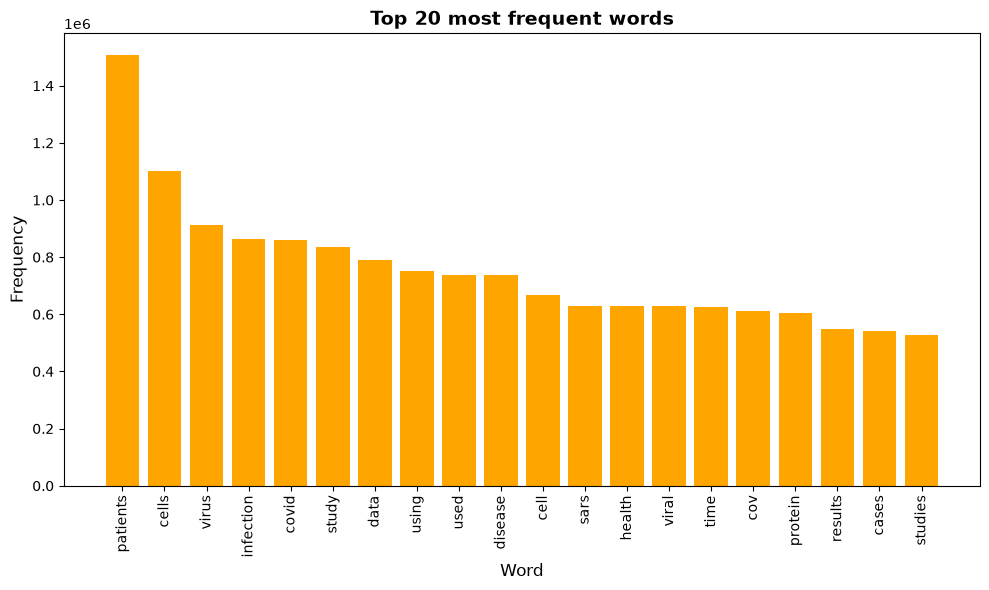

In [10]:
top20 = word_counts.sortBy(lambda x: -x[1]).take(20) #  descending order
print("\nTop 20 words:")
for word, count in top20:
    print(f"  {word:30s} {count:>10,}")
words = [w for w,c in top20]
count = [c for w,c in top20]
plt.figure(figsize=(10, 6))
plt.bar(words, count, color='orange')
plt.xlabel("Word", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.title("Top 20 most frequent words", fontsize=14, fontweight='bold')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [31]:
spark.stop()

### Benchmarking

In this work we investigate how number of partitions and executor configuration affects execution time.

All three configurations keep the total core count constant at 24 cores, but distribute them differently:

- 3 executors with 8 cores each
- 6 executors with 4 cores each
- 12 executors with 2 cores each

We tested partition counts relative to the total number of available cores $x = 24$, specifically:

$$[8, 12, 24, 48, 72] = \left[\frac{x}{3}, \frac{x}{2}, x, 2x, 3x\right]$$

To ensure statistical reliability, each configuration was repeated $n = 5$ times. The first repetition (rep=0) is excluded from the average. 

In [2]:
import matplotlib.pyplot as plt
import json
import sys
import re
import socket
from collections import Counter
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
import time
import pandas as pd
from pathlib import Path
import numpy as np
from pyspark.sql import SparkSession

[nltk_data] Downloading package stopwords to /home/ubuntu/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
#n_executors = [3, 6, 12]
#cores_per_executor = [8, 4, 2]
partition_values = [8, 12, 24, 48, 72]
n_repeats = 5
all_results = []

n_executors = 3 # 6, 12
cores_per_executor = 8 # 4, 2 

spark = SparkSession.builder \
    .master("spark://master:7077")\
    .appName("polly")\
    .config('spark.jars.packages', 'org.apache.hadoop:hadoop-aws:3.4.1,org.apache.hadoop:hadoop-common:3.4.1')\
    .config("spark.cores.max", cores_per_executor*n_executors) \
    .config("spark.executor.cores", cores_per_executor) \
    .config("spark.executor.instances", n_executors) \
    .config("spark.executor.memory", "3g") \
    .config("spark.local.dir", "/mnt/vol2/spark-tmp")\
    .config("spark.worker.dir", "/mnt/vol2/spark-tmp") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")\
    .config("spark.sql.execution.arrow.pyspark.fallback.enabled", "false")\
    .config('spark.hadoop.fs.s3a.aws.credentials.provider', 'org.apache.hadoop.fs.s3a.SimpleAWSCredentialsProvider')\
    .config('spark.hadoop.fs.s3a.access.key', 'KEY')\
    .config('spark.hadoop.fs.s3a.secret.key', 'KEY')\
    .config('spark.hadoop.fs.s3a.endpoint', 'https://cloud-areapd.pd.infn.it:5210')\
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .config("spark.hadoop.fs.s3a.metadatastore.impl", "org.apache.hadoop.fs.s3a.s3guard.NullMetadataStore") \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .config("spark.hadoop.fs.s3a.connection.ssl.enabled","false") \
    .config("com.amazonaws.sdk.disableCertChecking","true") \
    .getOrCreate()

sc = spark.sparkContext

def extract_text(path):
    try:
        with open(path) as f:
            doc = json.load(f)
    except Exception:
        return ""
    
    parts = []

    for block in doc.get("body_text", []):
        if block.get("text"):
            parts.append(block["text"])
            
    return " ".join(parts)

LATEX_STOPWORDS = {
    "usepackage","documentclass","documentstyle","newcommand",
    "renewcommand","def","let","newenvironment","setlength","setcounter",
    "addtolength","oddsidemargin","evensidemargin","textwidth","textheight",
    "topmargin","amsmath","amssymb","amsfonts","amsbsy","amsthm","amscd",
    "mathrsfs","mathtools","upgreek","wasysym","eucal","includegraphics",
    "bibliographystyle","bibliography","cite","ref","label","caption",
    "footnote","textbf","textit","emph","hline","vspace","hspace","noindent",
    "centering","linewidth","columnwidth","document","minimal",
    "figure","table","equation","align","array","itemize","enumerate",
}

EXTRA_STOPWORDS = {'also', 'may', 'however', 'one', 'two'}

STOPWORDS = set(stopwords.words('english')) | LATEX_STOPWORDS | EXTRA_STOPWORDS

def clean_text(text):
    clean_text = re.findall(r'[a-z]{3,}', text.lower()) 
    return [t for t in clean_text if t not in STOPWORDS]

def count_words(sc, rdd):
    t0 = time.time()
    
    word_counts = (
        rdd
        .map(lambda w: (w,1))
        .reduceByKey(lambda a, b: a + b)          
        .cache()
    )
    total_unique = word_counts.count()

    elapsed = time.time()-t0

    return word_counts, total_unique, elapsed

base_dir = Path("/mnt/vol2/.cache/kagglehub/datasets/allen-institute-for-ai/CORD-19-research-challenge/versions/50/document_parses/")
all_paths = list(base_dir.rglob("*.json"))
print(f"Total JSON files found in disk: {len(all_paths)}")

df_pandas=pd.read_csv('/mnt/vol2/.cache/kagglehub/directory.csv')
valid_files = set(df_pandas['path'])
all_path = [path for path in all_paths if path.name in valid_files]
print(f"Total JSON files to process (filtered): {len(all_path)}")

26/07/11 17:19:35 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


Total JSON files found in disk: 183369
Total JSON files to process (filtered): 128782


In [25]:
partition_values = [8, 12, 24, 48, 72]
n_repeats = 5
all_results = []

for n in partition_values:
    paths_rdd = sc.parallelize(all_path, numSlices=n)
    words_rdd = paths_rdd.map(extract_text).flatMap(clean_text)
    words_rdd.persist()
    for rep in range(n_repeats):
        print(f"Run with {n} partition values {rep+1} time: ")
        word_counts, total_unique, elapsed = count_words(
            sc, words_rdd
        )
        all_results.append({
            "num_executors": n_executors,
            "cores_per_executor": cores_per_executor,
            "total_cores": n_executors * cores_per_executor,
            "num_partitions": n,
            "rep": rep,
            "time_sec": elapsed
        })
        print(f"partitions={n} rep={rep} time={elapsed:.2f}s")
        word_counts.unpersist(blocking=True)
    words_rdd.unpersist(blocking = True)

df = pd.DataFrame(all_results)
df.to_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task1_3_8.csv", index=False)
print("Saved!")
print(df)

Run with 8 partition values 1 time: 


26/07/11 17:20:19 WARN TaskSetManager: Stage 0 contains a task of very large size (1213 KiB). The maximum recommended task size is 1000 KiB.
26/07/11 17:23:41 WARN TaskSetManager: Stage 2 contains a task of very large size (1292 KiB). The maximum recommended task size is 1000 KiB.


partitions=8 rep=0 time=202.16s
Run with 8 partition values 2 time: 


26/07/11 17:24:14 WARN TaskSetManager: Stage 4 contains a task of very large size (1213 KiB). The maximum recommended task size is 1000 KiB.


partitions=8 rep=1 time=32.79s
Run with 8 partition values 3 time: 


...

partitions=72 rep=1 time=15.47s
Run with 72 partition values 3 time: 


partitions=72 rep=2 time=15.09s
Run with 72 partition values 4 time: 


partitions=72 rep=3 time=15.30s
Run with 72 partition values 5 time: 


[Stage 49:======================================>                (51 + 21) / 72]

partitions=72 rep=4 time=15.12s
Saved!
    num_executors  cores_per_executor  total_cores  num_partitions  rep  \
0               3                   8           24               8    0   
1               3                   8           24               8    1   
2               3                   8           24               8    2   
3               3                   8           24               8    3   
4               3                   8           24               8    4   
5               3                   8           24              12    0   
6               3                   8           24              12    1   
7               3                   8           24              12    2   
8               3                   8           24              12    3   
9               3                   8           24              12    4   
10              3                   8           24              24    0   
11              3                   8           24           

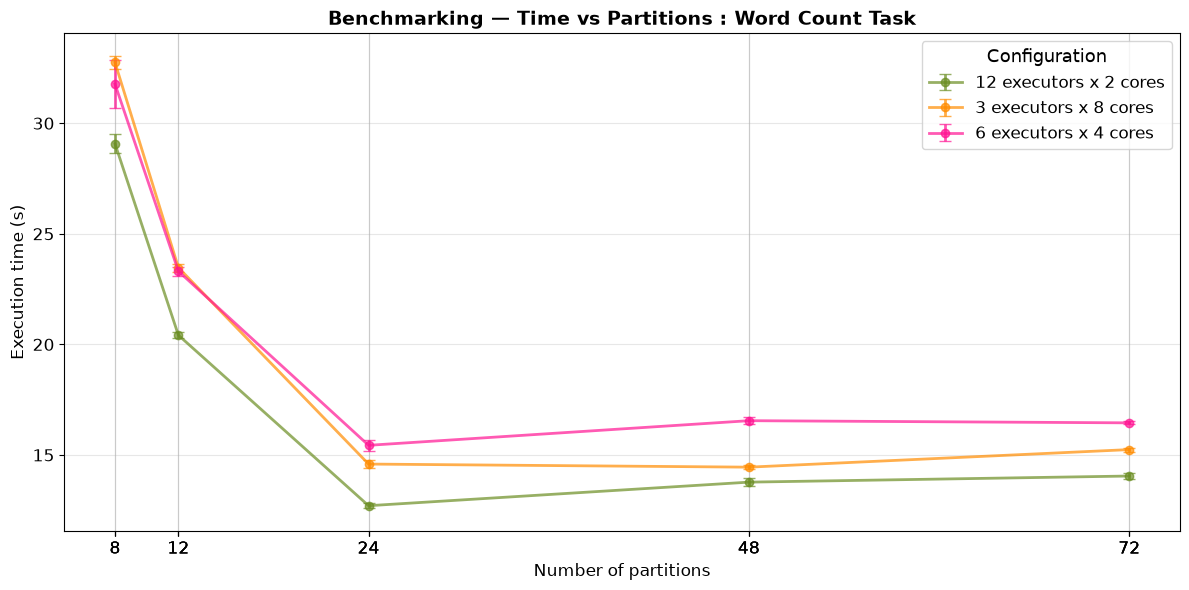

In [ ]:
df1 = pd.read_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task1_12_2.csv")
df2 = pd.read_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task1_3_8.csv")
df3 = pd.read_csv("/mnt/vol2/.cache/kagglehub/benchmarking_csv/task1_6_4.csv")


df_all = pd.concat([df1, df2, df3], ignore_index=True)

# drop the first repetition 
df_clean = df_all[df_all['rep'] != 0]

df_avg = (
    df_clean
    .groupby(['num_executors', 'cores_per_executor', 'num_partitions'])['time_sec']
    .agg(mean_time='mean', std_time='std', n='count')
    .reset_index()
)
df_avg['sem_time'] = df_avg['std_time'] / np.sqrt(df_avg['n'])

configs = [(12, 2), (3, 8), (6, 4)]
colors = [ 'olivedrab','darkorange' ,'deeppink']
labels = ['12 executors x 2 cores', '3 executors x 8 cores', '6 executors x 4 cores']

plt.figure(figsize=(12, 6))
for (n_ex, n_c), color, label in zip(configs, colors, labels):
    subset = df_avg[
        (df_avg['num_executors'] == n_ex) &
        (df_avg['cores_per_executor'] == n_c)
    ].sort_values('num_partitions')
    plt.errorbar(subset['num_partitions'], subset['mean_time'],
                 yerr=subset['sem_time'],
                 marker='o', color=color, alpha = 0.7, label=label,
                 linewidth=2, capsize=4)
plt.xticks(df_avg['num_partitions'], fontsize = 12)
plt.yticks(fontsize=12)
plt.xlabel('Number of partitions', fontsize = 12)
plt.ylabel('Execution time (s)', fontsize = 12)
plt.title('Benchmarking \n Time vs Partitions : Word Count Task', fontsize = 14, fontweight = 'bold') #Benchmarking Task 1
plt.legend(title='Configuration', fontsize = 12, title_fontsize = 13)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('/mnt/vol2/.cache/kagglehub/benchmarking_csv/plots/benchmarking_plot_task1.png', dpi=150)
plt.show()